# **Vertente explorada: Relação Cliente x Financeiro**

In [50]:
#%pip install scipy

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

## **Variáveis segmentadas por tema**

- *Cliente*
    - customerID: ID do cliente;
    - gender: Gênero;
    - SeniorCitizen: É idoso?;
    - Partner: É parceiro?;
    - Dependents: Tem dependentes?;

- *Financeiro*
    - MonthlyCharges: Cobranças mensais;
    - TotalCharges: Cobranças totais;
    - MonthlyIncome: Renda mensal.

## **Perguntas de Orientação**

In [52]:
df_silver = pd.read_csv("../Data/Silver/tabela_silver.csv")

- Criamos uma cópia para alterações

In [53]:
df = df_silver.copy()

### **Existe diferença entre a renda mensal de diferentes gêneros?**

In [54]:
colunas = ["ID_Cliente", "Genero", "Dependentes", "Idoso", "Renda_Mensal"]

In [55]:
df_gold01 = df[colunas].copy()

In [56]:
df_gold01.head()

,ID_Cliente,Genero,Dependentes,Idoso,Renda_Mensal
0,4578-PHJYZ,Masculino,True,False,6532.0
1,6289-CPNLD,Masculino,True,False,7634.0
2,2682-KEVRP,Feminino,False,True,3628.0
3,5697-GOMBF,Feminino,True,True,7851.0
4,9717-QEBGU,Masculino,False,False,1691.0


In [57]:
df_gold01.info()

<class 'pandas.DataFrame'>
RangeIndex: 5634 entries, 0 to 5633
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ID_Cliente    5634 non-null   str    
 1   Genero        5634 non-null   str    
 2   Dependentes   5634 non-null   bool   
 3   Idoso         5634 non-null   bool   
 4   Renda_Mensal  5634 non-null   float64
dtypes: bool(2), float64(1), str(2)
memory usage: 143.2 KB


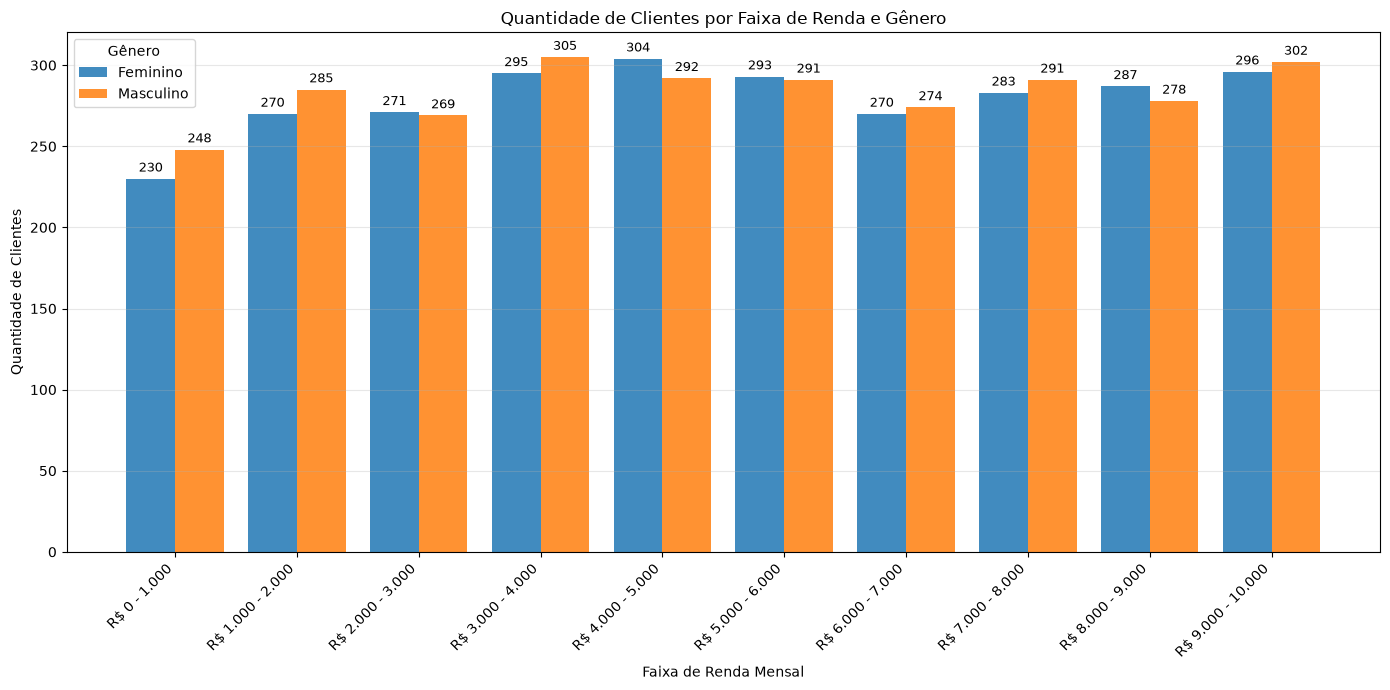

In [58]:

# Separação dos valores de renda por gênero
renda_feminino = df_gold01.loc[
    df_gold01["Genero"] == "Feminino", "Renda_Mensal"
].dropna()

renda_masculino = df_gold01.loc[
    df_gold01["Genero"] == "Masculino", "Renda_Mensal"
].dropna()

# Definição das faixas de renda a cada R$ 1.000
valor_minimo = int(
    df_gold01["Renda_Mensal"].min() // 1000 * 1000
)

valor_maximo = int(
    (df_gold01["Renda_Mensal"].max() // 1000 + 1) * 1000
)

faixas = np.arange(valor_minimo, valor_maximo + 1000, 1000)

# Contagem de clientes em cada faixa
quantidade_feminino, _ = np.histogram(
    renda_feminino,
    bins=faixas
)

quantidade_masculino, _ = np.histogram(
    renda_masculino,
    bins=faixas
)

# Posições das barras
posicoes = np.arange(len(faixas) - 1)
largura = 0.4

plt.figure(figsize=(14, 7))

# Barras femininas
barras_feminino = plt.bar(
    posicoes - largura / 2,
    quantidade_feminino,
    width=largura,
    label="Feminino",
    alpha=0.85
)

# Barras masculinas
barras_masculino = plt.bar(
    posicoes + largura / 2,
    quantidade_masculino,
    width=largura,
    label="Masculino",
    alpha=0.85
)

# Adicionar valores acima das barras
plt.bar_label(
    barras_feminino,
    padding=3,
    fontsize=9
)

plt.bar_label(
    barras_masculino,
    padding=3,
    fontsize=9
)

# Identificação das faixas de renda
rotulos = [
    f"R$ {faixas[i]:,.0f} - {faixas[i+1]:,.0f}".replace(",", ".")
    for i in range(len(faixas) - 1)
]

plt.xticks(posicoes, rotulos, rotation=45, ha="right")

plt.title("Quantidade de Clientes por Faixa de Renda e Gênero")
plt.xlabel("Faixa de Renda Mensal")
plt.ylabel("Quantidade de Clientes")
plt.legend(title="Gênero")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


- Uma pergunta dentro do tema, quantas desses clientes são idosos?

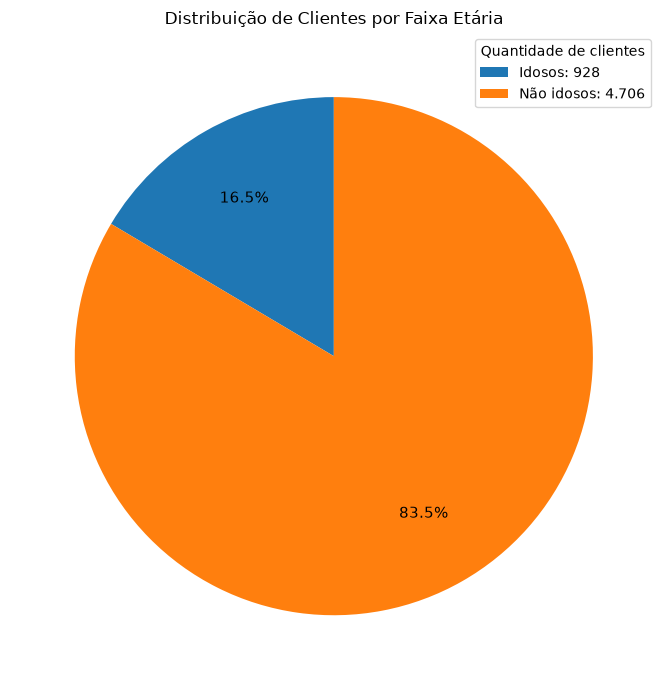

In [61]:
# Contagem de clientes por condição de idade
quantidade_idosos = df_gold01["Idoso"].value_counts().reindex(
    [True, False], fill_value=0
)

# Rótulos das categorias
rotulos = ["Idosos", "Não idosos"]

# Quantidades totais
quantidades = quantidade_idosos.values

# Criação do gráfico
plt.figure(figsize=(8, 7))

plt.pie(
    quantidades,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.7,
    textprops={"fontsize": 11}
)

# Legenda com as quantidades absolutas
plt.legend(
    [
        f"{rotulos[i]}: {quantidades[i]:,}".replace(",", ".")
        for i in range(len(rotulos))
    ],
    title="Quantidade de clientes",
    loc="best"
)

plt.title("Distribuição de Clientes por Faixa Etária")
plt.tight_layout()
plt.show()


- Quantos idosos possuem dependentes?

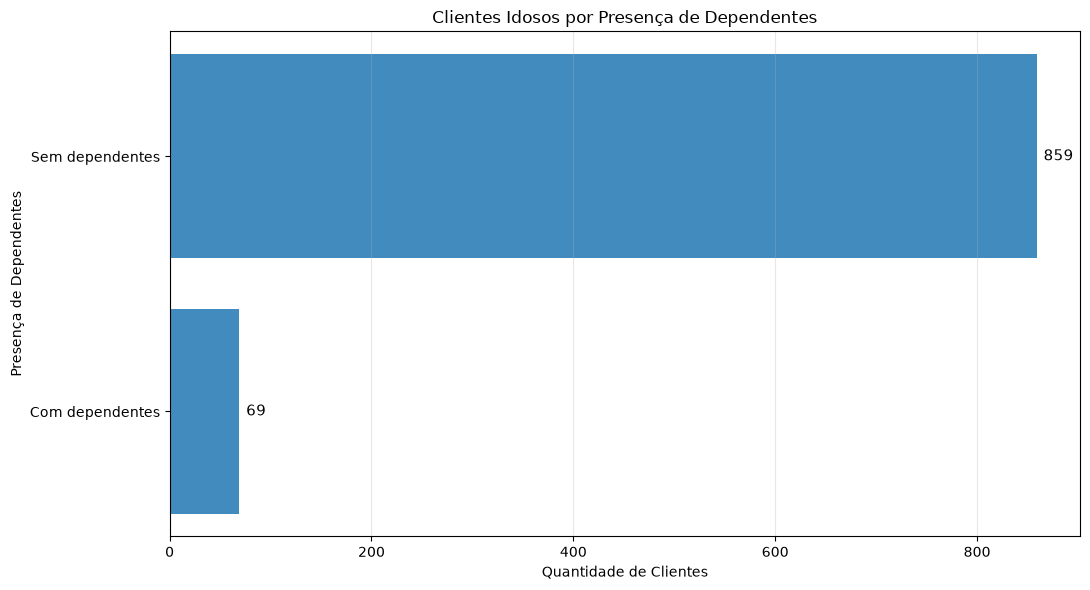

In [66]:

# Filtrar apenas clientes idosos
df_idosos = df_gold01[df_gold01["Idoso"] == True]

# Contabilizar clientes idosos por presença de dependentes
quantidade_dependentes = (
    df_idosos["Dependentes"]
    .value_counts()
    .reindex([True, False], fill_value=0)
)

# Criar gráfico de barras horizontal
plt.figure(figsize=(11, 6))

barras = plt.barh(
    ["Com dependentes", "Sem dependentes"],
    quantidade_dependentes.values,
    alpha=0.85
)

# Adicionar valores ao final das barras
plt.bar_label(
    barras,
    padding=5,
    fontsize=11
)

plt.title("Clientes Idosos por Presença de Dependentes")
plt.xlabel("Quantidade de Clientes")
plt.ylabel("Presença de Dependentes")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### **Se o cliente possui dependentes, sua renda mensal é maior?**

### **A média de cobrança mensal é distinta entre diferentes gêneros?**

### **Os idosos possuem cobranças mensais maiores do que não idosos?**

### **Se o cliente possui dependentes, suas cobranças totais são maiores?**

### **Se o cliente é idoso, suas cobranças totais são maiores?**